# CC08 · Aula 02 · Atividade no Colab

---


**Pipelines e paralelismo, medidos por você.** Prof. João Luisi

Individual, cerca de 30 minutos. Em cada parte: **anote o palpite antes de rodar**, rode, registre o número e responda.

**Antes de começar:** `Arquivo > Salvar uma cópia no Drive`. Rode as células em ordem (`Shift+Enter`).

**Entrega:** a célula de respostas no fim, preenchida. Baixe o notebook (`Arquivo > Baixar > .ipynb`) e entregue no portal.


## 0. Preparação (só rodar)

In [1]:
# Funções de apoio: rodam um comando e devolvem o número medido.
import re, subprocess
import matplotlib.pyplot as plt

def rodar(cmd):
    saida = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if saida.returncode != 0:
        print(saida.stderr)
    return saida.stdout.strip()

def numero(texto, unidade):
    return float(re.search(r"([\d.]+) " + unidade, texto).group(1))

def ghz():
    for linha in open("/proc/cpuinfo"):
        if linha.startswith("cpu MHz"):
            return float(linha.split(":")[1]) / 1000
print(f"Clock informado pelo sistema: {ghz():.2f} GHz")

Clock informado pelo sistema: 2.25 GHz


In [2]:
!lscpu | grep -E "Model name|^CPU\(s\)|Thread\(s\) per core|Core\(s\) per socket|L1d|L2|L3"

CPU(s):                                  2
Model name:                              AMD EPYC 7B12
Thread(s) per core:                      2
Core(s) per socket:                      1
L1d cache:                               32 KiB (1 instance)
L2 cache:                                512 KiB (1 instance)
L3 cache:                                16 MiB (1 instance)


In [3]:
%%writefile desvio.c
// desvio.c: soma so os elementos >= limiar. uso: ./desvio <limiar 0..256> <ordenado 0|1>
#include <stdio.h>
#include <stdlib.h>
#include <time.h>
#define N 1000000
static int cmp(const void *a, const void *b) { return *(const int *)a - *(const int *)b; }
static double agora(void) { struct timespec t; clock_gettime(CLOCK_MONOTONIC, &t); return t.tv_sec + t.tv_nsec * 1e-9; }
int main(int argc, char **argv) {
  int limiar = atoi(argv[1]), ordenado = atoi(argv[2]);
  int *v = malloc(N * sizeof(int));
  srand(42);
  for (int i = 0; i < N; i++) v[i] = rand() % 256;
  if (ordenado) qsort(v, N, sizeof(int), cmp);
  double melhor = 1e9; long long soma = 0;
  for (int r = 0; r < 15; r++) {
    double t0 = agora(); soma = 0;
    for (int i = 0; i < N; i++)
      if (v[i] >= limiar) soma += v[i];
    double t = agora() - t0; if (t < melhor) melhor = t;
  }
  printf("%.3f ms (soma=%lld)\n", melhor * 1e3, soma);
  return 0;
}

Writing desvio.c


In [4]:
# -O1 sem if-conversion e sem vetorização: o compilador mantém o desvio (o if) no código
!gcc -O1 -fno-if-conversion -fno-if-conversion2 -fno-tree-vectorize -o desvio desvio.c

In [5]:
%%writefile acum.c
// acum.c: soma de doubles com K acumuladores independentes. compilar com -DK=1, 2, 4...
#include <stdio.h>
#include <time.h>
#ifndef K
#define K 1
#endif
#define N 4200
static double agora(void) { struct timespec t; clock_gettime(CLOCK_MONOTONIC, &t); return t.tv_sec + t.tv_nsec * 1e-9; }
static double v[N];
int main(void) {
  for (int i = 0; i < N; i++) v[i] = 1.0 / (i + 1);
  double melhor = 1e9, total = 0;
  for (int r = 0; r < 20; r++) {
    double t0 = agora();
    double acc[K] = {0};
    for (int rep = 0; rep < 2000; rep++)
      for (int i = 0; i < N; i += K)
#pragma GCC unroll 16
        for (int k = 0; k < K; k++) acc[k] += v[i + k];
    double t = agora() - t0; if (t < melhor) melhor = t;
    total = 0; for (int k = 0; k < K; k++) total += acc[k];
  }
  printf("%.3f ns por soma (total=%.3f)\n", melhor * 1e9 / (2000.0 * N), total);
  return 0;
}

Writing acum.c


In [6]:
# um executável por número de acumuladores (K)
Ks = [1, 2, 3, 4, 6, 8, 10, 12]
for k in Ks:
    rodar(f"gcc -O2 -fno-tree-vectorize -DK={k} -o acum{k} acum.c")
print("compilado:", Ks)

compilado: [1, 2, 3, 4, 6, 8, 10, 12]


In [7]:
%%writefile smt.c
// smt.c: T threads, cada uma fazendo somas dependentes (dep) ou independentes (ind).
// uso: ./smt <dep|ind> <threads>
#include <pthread.h>
#include <stdio.h>
#include <string.h>
#include <stdlib.h>
#include <time.h>
#define PASSOS 200000000L
static int indep;
static double agora(void) { struct timespec t; clock_gettime(CLOCK_MONOTONIC, &t); return t.tv_sec + t.tv_nsec * 1e-9; }
static void *trabalha(void *arg) {
  double a = 1, b = 1, c = 1, d = 1, x = 1e-9;
  if (indep) for (long i = 0; i < PASSOS / 4; i++) { a += x; b += x; c += x; d += x; }
  else for (long i = 0; i < PASSOS; i++) a += x;
  double *r = malloc(sizeof(double)); *r = a + b + c + d; return r;
}
int main(int argc, char **argv) {
  indep = strcmp(argv[1], "ind") == 0; int T = atoi(argv[2]);
  pthread_t t[64]; double t0 = agora(), s = 0;
  for (int i = 0; i < T; i++) pthread_create(&t[i], NULL, trabalha, NULL);
  for (int i = 0; i < T; i++) { void *r; pthread_join(t[i], &r); s += *(double *)r; free(r); }
  double dt = agora() - t0;
  printf("%.2f s; %.2f somas por ns no total (s=%.1f)\n", dt, T * PASSOS / dt * 1e-9, s);
  return 0;
}

Writing smt.c


In [8]:
!gcc -O2 -pthread -o smt smt.c

## Parte 1. A curva do previsor de desvio
O programa `desvio` soma só os elementos maiores ou iguais a um **limiar**, num vetor de 1 milhão de números entre 0 e 255. Vamos variar o limiar de 0 a 256, com o vetor embaralhado e ordenado.

**Palpite (antes de rodar):** em que limiar o vetor embaralhado vai ser mais lento? Escreva na célula de respostas.

limiar   0: embaralhado  0.703 ms   ordenado  0.702 ms
limiar  32: embaralhado  1.613 ms   ordenado  0.812 ms
limiar  64: embaralhado  2.887 ms   ordenado  0.755 ms
limiar  96: embaralhado  3.554 ms   ordenado  1.113 ms
limiar 128: embaralhado  4.285 ms   ordenado  1.022 ms
limiar 160: embaralhado  3.423 ms   ordenado  0.507 ms
limiar 192: embaralhado  2.604 ms   ordenado  0.751 ms
limiar 224: embaralhado  1.655 ms   ordenado  0.735 ms
limiar 256: embaralhado  0.667 ms   ordenado  0.626 ms


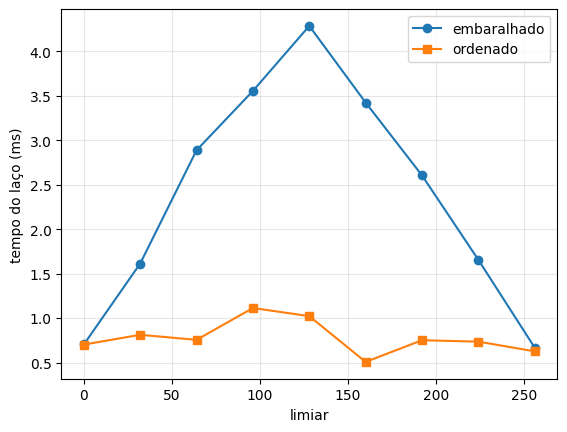

In [9]:
limiares = list(range(0, 257, 32))
emb = [numero(rodar(f"./desvio {l} 0"), "ms") for l in limiares]
ordn = [numero(rodar(f"./desvio {l} 1"), "ms") for l in limiares]
for l, e, o in zip(limiares, emb, ordn):
    print(f"limiar {l:3d}: embaralhado {e:6.3f} ms   ordenado {o:6.3f} ms")
plt.plot(limiares, emb, "o-", label="embaralhado")
plt.plot(limiares, ordn, "s-", label="ordenado")
plt.xlabel("limiar"); plt.ylabel("tempo do laço (ms)"); plt.legend(); plt.grid(alpha=.3)
plt.show()

**Responda na célula final:**
- **1a.** Em que limiar o embaralhado é mais lento? Por que ali, e por que os limiares 0 e 256 são rápidos?
- **1b.** Estime quanto custa **um** erro de previsão, em ns e em ciclos. Dica: no limiar 128, cerca de metade das previsões erra no vetor embaralhado, e o ordenado quase não erra. Use o clock da célula 0.
- **1c.** Por que a curva do ordenado é quase plana?

## Parte 2. Até onde vão os acumuladores?
Somar com **K** acumuladores cria K cadeias de somas independentes. Vamos de K = 1 a K = 12.

**Palpite:** a partir de que K o tempo para de cair?

K =  1: 0.937 ns por soma (2.11 ciclos)
K =  2: 0.467 ns por soma (1.05 ciclos)
K =  3: 0.310 ns por soma (0.70 ciclos)
K =  4: 0.240 ns por soma (0.54 ciclos)
K =  6: 0.157 ns por soma (0.35 ciclos)
K =  8: 0.157 ns por soma (0.35 ciclos)
K = 10: 0.157 ns por soma (0.35 ciclos)
K = 12: 0.157 ns por soma (0.35 ciclos)


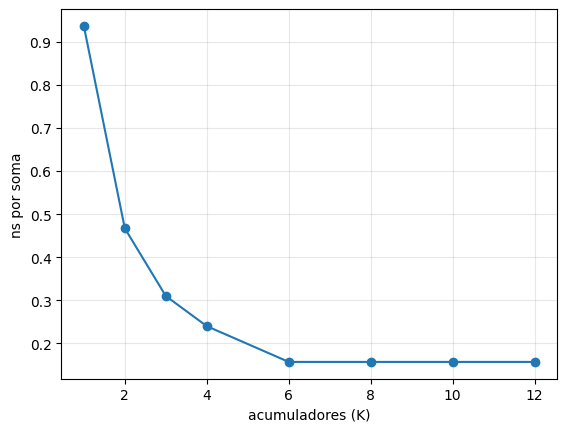

In [10]:
tempos = [numero(rodar(f"./acum{k}"), "ns") for k in Ks]
for k, t in zip(Ks, tempos):
    print(f"K = {k:2d}: {t:.3f} ns por soma ({t * ghz():.2f} ciclos)")
plt.plot(Ks, tempos, "o-")
plt.xlabel("acumuladores (K)"); plt.ylabel("ns por soma"); plt.grid(alpha=.3)
plt.show()

**Responda:**
- **2a.** Em que K a curva para de melhorar?
- **2b.** Com K = 1, quantos ciclos custa cada soma? Isso mede a **latência** ou a **vazão** da unidade de soma? Por quê?
- **2c.** Se cada soma tem a latência que você achou em 2b e a curva para em K da 2a, quantas somas o núcleo consegue começar por ciclo? Mostre a conta.

## Parte 3. Duas threads no mesmo núcleo
O programa `smt` roda 1 ou 2 threads; cada uma faz somas em cadeia (`dep`) ou em quatro cadeias independentes (`ind`). A saída é o total de somas por nanossegundo.

Olhe a saída do `lscpu` na preparação: quantas **threads por núcleo** a sua máquina tem?

**Palpite:** com 2 threads, em qual modo o total cresce mais, `dep` ou `ind`?

In [11]:
for modo in ["dep", "ind"]:
    um = numero(rodar(f"./smt {modo} 1"), "somas")
    dois = numero(rodar(f"./smt {modo} 2"), "somas")
    print(f"{modo}: 1 thread {um:.2f} somas/ns; 2 threads {dois:.2f} somas/ns; ganho {dois / um:.2f}")

dep: 1 thread 1.05 somas/ns; 2 threads 2.09 somas/ns; ganho 1.99
ind: 1 thread 4.23 somas/ns; 2 threads 8.26 somas/ns; ganho 1.95


**Responda:**
- **3a.** Qual foi o ganho de 2 threads em cada modo?
- **3b.** Explique a diferença usando o que a unidade de soma faz a cada ciclo em cada modo. Se a sua máquina tem 1 thread por núcleo, explique o que muda.

## Parte 4. A decisão
O interpretador do módulo de controle do projeto confere, a cada instrução da rotina, se o botão foi apertado. Duas opções:

- **A · Manter o `if`.** Quando o previsor acerta, é quase de graça; quando erra, paga o custo que você mediu na 1b.
- **B · Trocar por código sem desvio.** Sempre o mesmo tempo, um pouco maior que o `if` bem previsto, e sem depender do previsor.

Não existe resposta certa: as duas têm custo. Responda com: (1) a decisão na primeira frase, sem "depende"; (2) do que você abre mão e quem sente isso; (3) um número seu da Parte 1, e como ele pesou; (4) o que faria você mudar de ideia.

## Respostas
Nome: Maria Clara Oliveira Santos

**Palpites (antes de rodar):**

**Parte 1:** O meu palpite é que as limiares mais para o meio (por volta de 128) vão ser mais lentos. Isso se deve ao fato de que o programa acabará ignorando metade dos números, o que influenciará diretamente na previsão dos desvios (tornando o programa mais lento) Valores mais nos cantos (como 0 e 256) são mais previsíveis, logo o programa deve rodar mais rápido.

**Parte 2:** O enunciado diz que somar com K acumuladores cria K cadeias de somas independentes. No código, entendi que a linha `acc[k] += v[i + k]` espalha os números entre K variáveis diferentes, em vez de jogar tudo numa só, e que o programa é compilado uma vez para cada K da lista. Com 1 acumulador, cada soma precisa esperar a anterior terminar. Com mais acumuladores, várias somas podem estar em andamento ao mesmo tempo, mas o núcleo tem um limite de quantas somas consegue começar por ciclo, e eu lembrava que esse limite aparecia por volta de 4 acumuladores, a partir dos quais 8 já não melhorava. Então imagino que o tempo vai cair bastante de K = 1 até mais ou menos K = 4 e depois parar de cair. Pode ser um pouco antes ou depois, porque depende do processador da máquina do Colab.

**Parte 3:** O lscpu da preparação mostrou 2 threads por núcleo, então entendi que as duas threads vão dividir o mesmo núcleo. Pelo enunciado e pelo código, no modo `dep` cada thread soma tudo numa variável só (`a += x`), então cada soma depende da anterior. No modo `ind` são quatro variáveis (a, b, c, d) somando em paralelo. No SMT, o núcleo usa a segunda thread para preencher os espaços que ficariam vazios enquanto a primeira está esperando. No `dep`, a thread passa bastante tempo esperando a soma anterior, então deve sobrar espaço para a outra, e acho que o total quase dobra. No `ind`, uma thread sozinha já ocupa mais a unidade de soma, então sobra menos espaço e o ganho deve ser menor. Meu palpite: o total cresce mais no `dep`.

**Máquina usada (célula 0):** AMD EPYC 7B12, 1 núcleo com 2 threads por núcleo, clock informado de 2,25 GHz.

**1a.** O vetor embaralhado é mais lento no limiar 128, com 4,285 ms, contra 0,703 ms no limiar 0 e 0,667 ms no 256. No 128, metade dos números (de 0 a 255, aleatórios) passa no `if` e metade não, em ordem aleatória. O previsor de desvio tenta adivinhar o próximo resultado pelo histórico, mas numa sequência aleatória 50/50 não há padrão para aprender, e ele erra mais ou menos metade das vezes. Cada erro descarta as instruções que já tinham entrado no pipeline pelo caminho errado. No limiar 0, todo elemento passa, e no 256 nenhum passa; nos dois casos o desvio dá sempre o mesmo resultado, o previsor acerta quase 100% e o laço roda no ritmo do pipeline cheio. Entre os extremos, a curva tem forma de tenda: quanto mais perto de 50/50, mais erros.

**1b.** No limiar 128, o vetor ordenado também soma metade dos elementos, então o trabalho útil é o mesmo, e a diferença de tempo vem dos erros de previsão:

- diferença = 4,285 − 1,022 = 3,263 ms
- erros ≈ metade de 1.000.000 = 500.000
- custo de um erro = 3,263 ms / 500.000 ≈ 6,5 ns
- em ciclos, com o clock da célula 0: 6,5 ns × 2,25 GHz ≈ 14,7 ciclos

O valor de 2,25 GHz é o clock nominal informado pela VM, e a Parte 2 indica que o processador rodava perto de 3,2 GHz (ver 2b). Com esse clock, o erro custaria cerca de 21 ciclos. Nos dois casos, o custo fica na faixa de 15 a 20 ciclos, que corresponde à profundidade do pipeline que precisa ser esvaziado e recarregado.

**1c.** Ordenado, o vetor tem primeiro todos os elementos abaixo do limiar e depois todos os de cima. O `if` dá "não" seguidas vezes e, a partir de um ponto, "sim" até o fim. O previsor erra só alguns desvios perto dessa única troca e acerta o resto. São poucos erros em 1 milhão, qualquer que seja o limiar, por isso a curva fica quase plana, entre 0,51 e 1,11 ms; essa variação vem do ruído de medição e do trabalho extra das somas.

**2a.** A curva para de melhorar em K = 6, com 0,157 ns por soma, e continua em 0,157 ns com K = 8, 10 e 12.

**2b.** Com K = 1, cada soma custa 0,937 ns, ou 2,11 ciclos pelo clock da célula 0. Esse valor mede a latência da unidade de soma de ponto flutuante. Com um único acumulador, cada `acc[0] += v[i]` precisa do resultado da soma anterior, e a seguinte só começa quando a anterior termina. O tempo por soma é, portanto, o tempo que uma soma leva do início ao fim, e não a quantidade de somas que a unidade aceita por ciclo.

A soma de ponto flutuante do Zen 2 (arquitetura do EPYC 7B12) tem latência documentada de 3 ciclos. Se 3 ciclos levam 0,937 ns, o clock real é 3 / 0,937 ≈ 3,2 GHz (turbo), acima dos 2,25 GHz que a VM informa.

**2c.** Com K cadeias independentes, o núcleo termina K somas a cada intervalo de uma latência (L), o que dá K / L somas por ciclo até chegar ao limite de vazão. Como a curva parou em K = 6:

- pelos números medidos, vazão = 6 / L = 6 / 2,11 ≈ 2,8 somas por ciclo. Pelo gráfico, 0,157 ns equivalem a 0,35 ciclo por soma, e 1 / 0,35 ≈ 2,86. Sem usar o clock, 0,937 / 0,157 ≈ 6 somas começam no tempo de uma latência;
- com a latência real de 3 ciclos, a vazão é 6 / 3 = 2 somas por ciclo. Esse valor bate com o Zen 2, que tem duas unidades de soma em ponto flutuante: são necessárias 3 somas em andamento em cada uma, ou 2 × 3 = 6 cadeias, para manter as duas ocupadas. O 2,8 sai inflado porque o clock informado (2,25 GHz) está abaixo do real, então o valor mais confiável é 2 somas por ciclo.

**3a.** A célula 0 informa 2 threads por núcleo.
- `dep`: de 1,05 para 2,09 somas/ns, ganho de 1,99.
- `ind`: de 4,23 para 8,26 somas/ns, ganho de 1,95.

**3b.** Se as 2 threads dividissem de fato o mesmo núcleo (SMT), o esperado seria:
- `dep`: uma thread só começa 1 soma a cada 3 ciclos, porque cada soma espera a anterior. As 2 unidades de soma ficam livres quase todo o tempo (1/3 de soma por ciclo, de 2 possíveis), a segunda thread ocupa esses ciclos ociosos, e o ganho fica perto de 2.
- `ind`: uma thread com 4 cadeias já começa 4/3 ≈ 1,33 soma por ciclo (4,23 somas/ns ÷ 3,2 GHz ≈ 1,32). Sobram só 0,67 soma por ciclo para a segunda thread, e o ganho máximo seria 2 / 1,33 = 1,5.

A medição não confirma isso, porque o `ind` também quase dobrou (1,95). Com 2 threads, ele fez 8,26 somas/ns ÷ 3,2 GHz ≈ 2,6 somas por ciclo, mais do que as 2 por ciclo que um núcleo Zen 2 consegue fazer. Logo, as duas threads não estavam no mesmo núcleo físico. O Colab é uma máquina virtual: o `lscpu` mostra a topologia que o hipervisor declara (2 threads por núcleo), mas o hipervisor pode colocar as duas vCPUs em núcleos físicos diferentes do servidor. Cada thread fica com as próprias unidades de soma, como numa máquina com 1 thread por núcleo, e as duas escalam perto de 2 vezes em qualquer modo. O SMT só faria diferença entre `dep` e `ind` se as threads disputassem as mesmas unidades de soma.

**4.** Escolho a opção A: manter o `if`.

*Do que abro mão:* do tempo constante. Com o `if`, o tempo de cada instrução deixa de ser sempre o mesmo, porque na instrução em que o botão muda de estado o previsor erra e ela custa cerca de 6,5 ns a mais. Quem sente isso é o time de firmware, que calcula o pior caso de tempo do módulo de controle e passa a ter que somar o custo de um erro de previsão ao orçamento. A pessoa que aperta o botão não percebe 6,5 ns.

*O número que pesou:* 6,5 ns (cerca de 15 ciclos) por erro de previsão, calculado em 1b. O botão fica parado quase o tempo todo, então o desvio "não apertado" é tão previsível quanto o limiar 0 ou 256 da Parte 1. O previsor só erra quando o estado muda, ao apertar e ao soltar. Num interpretador que roda 10 milhões de instruções por segundo, com o botão apertado 5 vezes por segundo, a opção A erra cerca de 10 vezes por segundo, o que soma 10 × 6,5 ns = 65 ns por segundo. A opção B, mesmo custando só 1 ciclo a mais por instrução (0,44 ns a 2,25 GHz), soma 10⁷ × 0,44 ns = 4,4 ms por segundo, dezenas de milhares de vezes mais.

*O que me faria mudar de ideia:* o resultado da verificação deixar de ser previsível. A troca compensa quando a taxa de erro × 14,7 ciclos passa do ciclo extra da opção B, ou seja, com mais de 7% de erros de previsão (1 / 14,7 ≈ 6,8%). Isso aconteceria, por exemplo, se a verificação passasse a testar um sinal com ruído, que muda quase a cada instrução. Também mudaria de ideia se o módulo ganhasse um requisito de tempo real rígido, em que o pior caso precisa ser idêntico em toda instrução.
